# 03 · Caso 1 — otimização: produção máxima e lucro máximo

Reprodução da Seção 6.1 do artigo: Figs. 13–16 e Tabela 13. O problema de otimização
(Eq. 24) acopla o simulador de rede (que especifica vazões) ao modelo de reservatório
$Q_L = PI\,(P_{res} - P_{downhole})$ por meio de uma restrição de igualdade, resolvido com
programação quadrática sequencial (SLSQP do SciPy, equivalente ao `fmincon` usado no artigo).

Os problemas são os do bloco `study.optimizations` de `cases/case1_single_well.json`
(os mesmos que `gaslift run case1` resolve); cada resultado é comparado com o ótimo do
MATLAB (`data/reference/matlab_optimization_results.json`) e, quando impresso, com o valor
do artigo (`data/reference/published_tables.json`).

Referência: de Souza, J.N.M., de Medeiros, J.L., Costa, A.L.H., Nunes, G.C. (2010).
*Modeling, simulation and optimization of continuous gas lift systems for deepwater
offshore petroleum production*. Journal of Petroleum Science and Engineering 72 (3–4),
277–289, doi:10.1016/j.petrol.2010.03.028.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
REF = ROOT / "data" / "reference"
published = json.load(open(REF / "published_tables.json"))   # Tables 13-19 as printed in the paper
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from gaslift import tables
from gaslift.cases import load_case
from gaslift.plotting import plot_rate_contours
from gaslift.study import build_problem, initial_vector, load_reference, optimization_record, simulation_options
from gaslift.sweeps import sweep_rates

case = load_case("case1")
matlab = load_reference("matlab_optimization_results.json")
specs = {s["name"]: s for s in case.study["optimizations"]}
records = {}

def optimise(name):
    spec = specs[name]
    prob = build_problem(case, spec)
    t0 = time.perf_counter()
    res = prob.solve(initial_vector(prob, spec, records))
    records[name] = optimization_record(name, spec, res, time.perf_counter() - t0, matlab.get(spec.get("reference")))
    return res

pd.DataFrame([{"problem": s["name"], "paper": ", ".join(s["paper"]), "objective": s["objective"],
               "reservoir": s["reservoirs"][0], "bounds": (s["oil_bounds"], s["gas_bounds"])} for s in specs.values()]).set_index("problem")

,paper,objective,reservoir,bounds
problem,,,,
fig13_180bar,"Fig. 13, Fig. 14",max_production,"{'pressure': 180.0, 'productivity_index': None}","([5.0, 20.0], [1.0, 4.0])"
fig13_200bar,"Fig. 13, Fig. 14",max_production,"{'pressure': 200.0, 'productivity_index': None}","([5.0, 20.0], [1.0, 4.0])"
fig13_220bar,"Fig. 13, Fig. 14",max_production,"{'pressure': 220.0, 'productivity_index': None}","([5.0, 20.0], [1.0, 4.0])"
fig13_240bar,"Fig. 13, Fig. 14",max_production,"{'pressure': 240.0, 'productivity_index': None}","([5.0, 20.0], [1.0, 4.0])"
fig13_260bar,"Fig. 13, Fig. 14",max_production,"{'pressure': 260.0, 'productivity_index': None}","([5.0, 20.0], [1.0, 4.0])"
fig15_pi0.5,Fig. 15,max_production,"{'pressure': 220.0, 'productivity_index': 0.5}","([5.0, 20.0], [1.0, 4.0])"
fig15_pi1,"Fig. 15, Table 13 (Max)",max_production,"{'pressure': 220.0, 'productivity_index': 1.0}","([5.0, 20.0], [1.0, 4.0])"
fig15_pi2,Fig. 15,max_production,"{'pressure': 220.0, 'productivity_index': 2.0}","([5.0, 20.0], [1.0, 4.0])"
fig15_pi5,Fig. 15,max_production,"{'pressure': 220.0, 'productivity_index': 5.0}","([5.0, 20.0], [1.0, 4.0])"


## 6.1.1 · Produção máxima para diferentes pressões de fundo (Figs. 13 e 14)

Índice de produtividade infinito: a pressão de fundo é igual à pressão do reservatório.
A superfície da produção é muito plana na direção da vazão de gás perto do ótimo, de modo que
otimizadores diferentes podem parar em vazões de gás ligeiramente distintas com a mesma
produção (compare as colunas Python e MATLAB; a 260 bar o SLSQP encontra produção um pouco
maior que a publicada).

In [3]:
for p in (180, 200, 220, 240, 260):
    optimise(f"fig13_{p}bar")
fig13 = tables.fig13_table(records)
fig13

,oil (kg/s),gas (kg/s),oil MATLAB (kg/s),gas MATLAB (kg/s),evaluations,time (s)
P_well (bar),,,,,,
180,6.1093,1.8604,6.1093,1.8605,28,1.6280
200,8.3135,1.8412,8.3133,1.8421,22,1.4718
220,10.8630,1.7693,10.8630,1.7718,24,1.5074
240,13.7246,1.6542,13.7246,1.6542,24,1.4901
260,16.3180,1.7095,16.2843,1.6047,104,3.9145


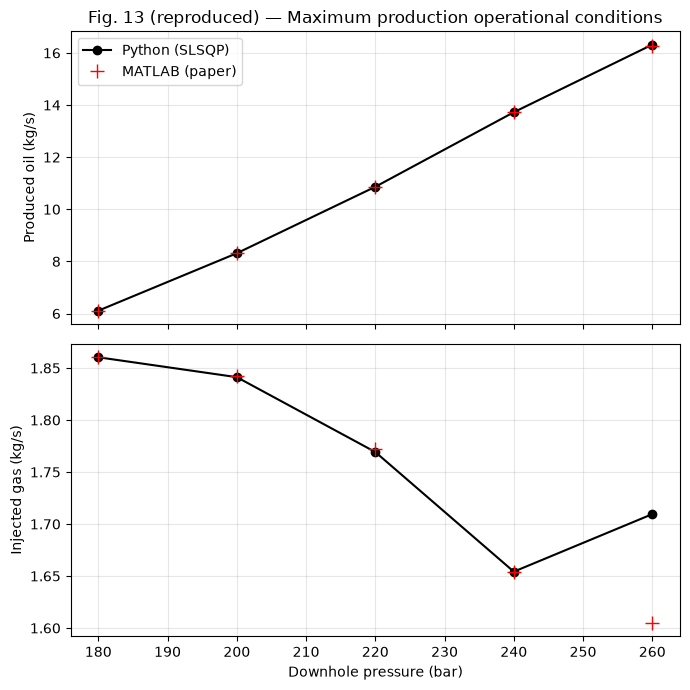

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
axes[0].plot(fig13.index, fig13["oil (kg/s)"], "ko-", label="Python (SLSQP)"); axes[0].plot(fig13.index, fig13["oil MATLAB (kg/s)"], "r+", ms=10, label="MATLAB (paper)")
axes[0].set_ylabel("Produced oil (kg/s)"); axes[0].legend(); axes[0].set_title("Fig. 13 (reproduced) — Maximum production operational conditions")
axes[1].plot(fig13.index, fig13["gas (kg/s)"], "ko-"); axes[1].plot(fig13.index, fig13["gas MATLAB (kg/s)"], "r+", ms=10)
axes[1].set_ylabel("Injected gas (kg/s)"); axes[1].set_xlabel("Downhole pressure (bar)")
plt.tight_layout()

> Compare com a Fig. 13 do artigo (a figura original não é distribuída com o repositório). O texto do artigo (Seção 6.1.1) afirma que a vazão ótima de gás varia de 1,55 a 1,85 kg/s.

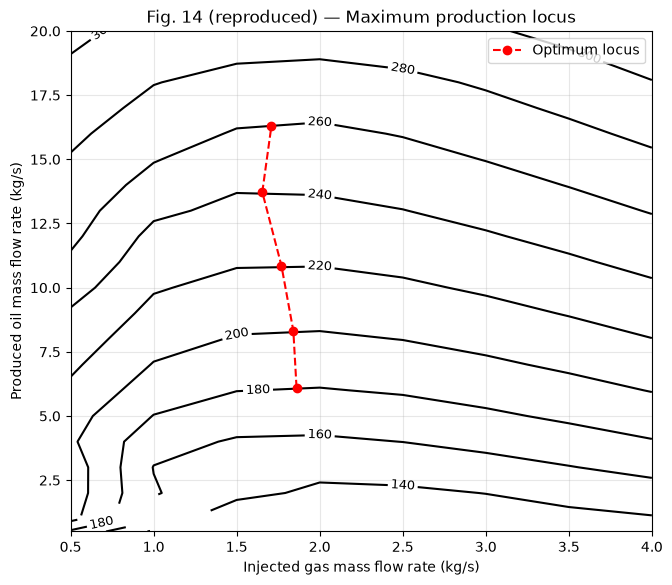

In [5]:
sweep_spec = next(s for s in case.study["sweeps"] if s["name"] == "fig06_fig07_2in")
sweep = sweep_rates(case.copy(), np.array(sweep_spec["q_gas"]), np.array(sweep_spec["q_oil"]), simulation_options(sweep_spec["rtol"]))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
plot_rate_contours(sweep.q_gas, sweep.q_oil, sweep.downhole(0), ax, np.arange(140, 320, 20), title="Fig. 14 (reproduced) — Maximum production locus")
ax.plot(fig13["gas (kg/s)"], fig13["oil (kg/s)"], "ro--", label="Optimum locus"); ax.legend(loc="upper right");

> Compare com a Fig. 14 do artigo (a figura original não é distribuída com o repositório).

## 6.1.2 · Produção máxima para diferentes índices de produtividade (Fig. 15)

In [6]:
for pi in (0.5, 1.0, 2.0, 5.0, 10.0):
    optimise(f"fig15_pi{pi:g}")
fig15 = tables.fig15_table(records)
fig15

,oil (kg/s),gas (kg/s),P_downhole (bar),oil MATLAB (kg/s),gas MATLAB (kg/s),P_downhole MATLAB (bar),time (s)
PI ((kg/s)/bar),,,,,,,
0.5,8.6403,1.8355,202.7196,8.6402,1.8355,202.7195,1.4853
1.0,9.5980,1.8119,210.4025,9.5979,1.8118,210.4021,1.3890
2.0,10.1827,1.7946,214.9095,10.1826,1.7944,214.9087,1.4377
5.0,10.5778,1.7803,217.8850,10.5778,1.7815,217.8844,1.5516
10.0,10.7181,1.7752,218.9286,10.7180,1.7768,218.9282,1.5320


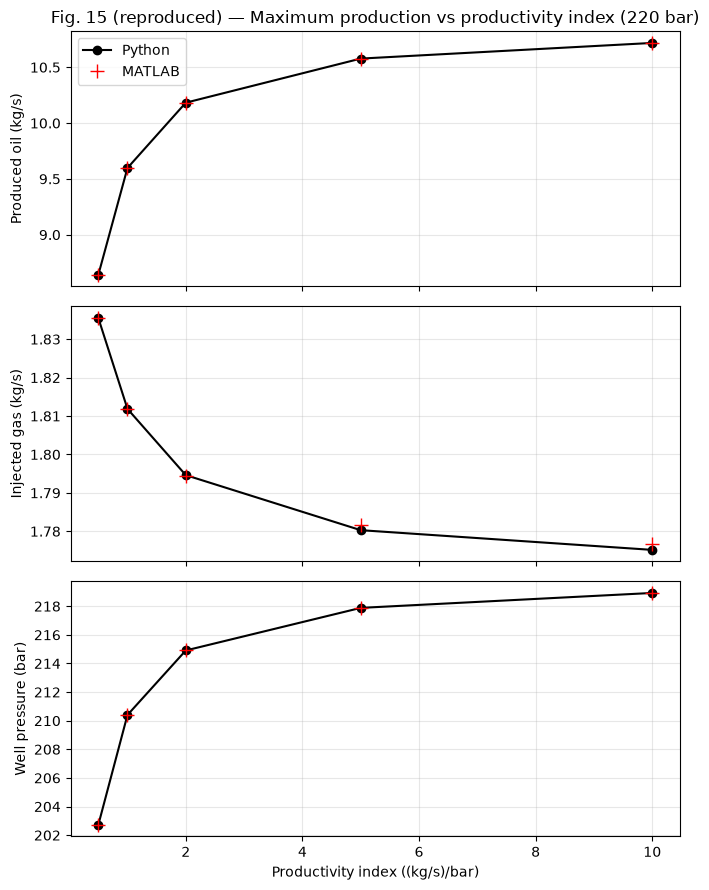

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(7, 9), sharex=True)
for ax, col, ref, lab in zip(axes, ["oil (kg/s)", "gas (kg/s)", "P_downhole (bar)"], ["oil MATLAB (kg/s)", "gas MATLAB (kg/s)", "P_downhole MATLAB (bar)"],
                             ["Produced oil (kg/s)", "Injected gas (kg/s)", "Well pressure (bar)"]):
    ax.plot(fig15.index, fig15[col], "ko-", label="Python"); ax.plot(fig15.index, fig15[ref], "r+", ms=10, label="MATLAB"); ax.set_ylabel(lab)
axes[0].legend(); axes[0].set_title("Fig. 15 (reproduced) — Maximum production vs productivity index (220 bar)"); axes[-1].set_xlabel("Productivity index ((kg/s)/bar)")
plt.tight_layout()

> Compare com a Fig. 15 do artigo (a figura original não é distribuída com o repositório).

## 6.1.3 · Lucro máximo (Tabela 13 e Fig. 16)

Função objetivo $\Omega_2 = R - AGC$: receita do óleo menos custo do gás combustível da
turbina do compressor (Eqs. 26, 31, 34 e 35). Os cenários variam o preço do óleo com o preço
do gás fixo em 0,1886 USD/Nm³; o cenário "Max" corresponde à produção máxima (custo nulo),
já calculado acima (`fig15_pi1`). A tabela mostra, lado a lado, os valores recalculados e os
impressos na Tabela 13 do artigo.

In [8]:
for scenario in ("1", "2", "3"):
    optimise(f"table13_scenario{scenario}")
table13 = tables.table13(records, published)
table13.rename_axis("Table 13 — Case 1 maximum profit results")

,Scenario 1,Scenario 1 (paper),Scenario 2,Scenario 2 (paper),Scenario 3,Scenario 3 (paper),Scenario Max,Scenario Max (paper)
Table 13 — Case 1 maximum profit results,,,,,,,,
Cost ratio (10³ (USD/Nm³)/(USD/bbl)),14.7445,14.7400,7.3722,7.3700,3.6868,3.6900,0.0000,0.000
Fuel gas cost (USD/Nm³),0.1886,0.1886,0.1886,0.1886,0.1886,0.1886,0.0000,0.000
Oil price (USD/barrel),12.7900,12.7900,25.5800,25.5800,51.1500,51.1500,51.1500,51.150
Produced oil (kg/s),9.5710,9.5710,9.5907,9.5910,9.5961,9.5960,9.5980,9.598
Injected gas (kg/s),1.6583,1.6580,1.7304,1.7300,1.7697,1.7700,1.8119,1.812
Downhole pressure (bar),210.4291,210.4300,210.4099,210.4100,210.4045,210.4000,210.4025,210.400
Compressor power (kW),1002.6255,1002.7000,1051.8648,1051.8000,1078.9370,1078.9000,1108.1221,1108.100
Discharge pressure P_G (bar),269.1781,269.1800,274.0392,274.0300,276.7447,276.7400,279.6852,279.680
Profit (10⁶ USD/yr),26.9630,26.9600,55.5625,55.5600,112.8224,112.8200,114.5644,114.560


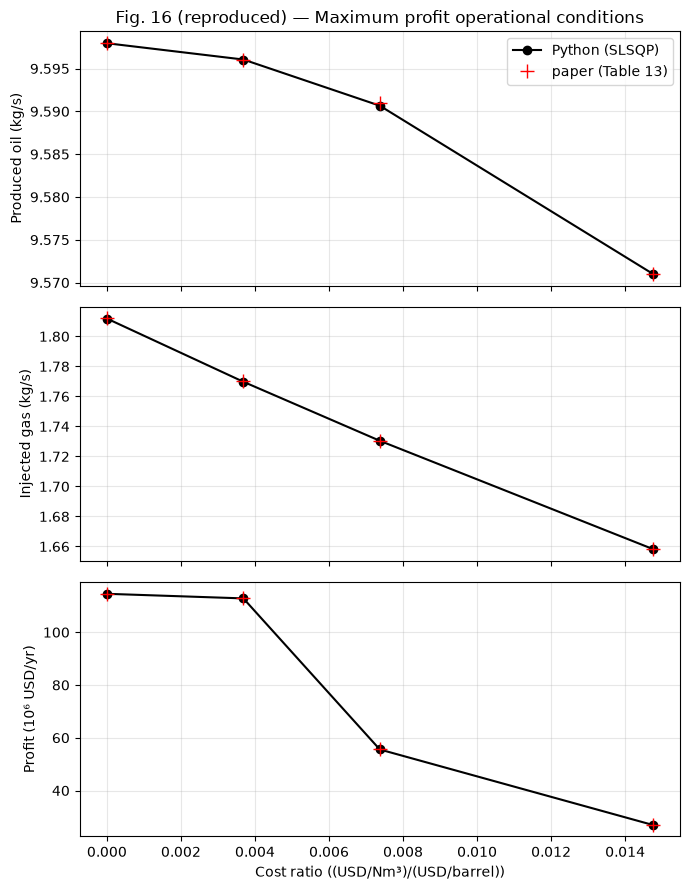

In [9]:
cols = [c for c in table13.columns if "(paper)" not in c]
pcols = [c + " (paper)" for c in cols]
ratio = table13.loc["Cost ratio (10³ (USD/Nm³)/(USD/bbl))", cols].astype(float) / 1e3
fig, axes = plt.subplots(3, 1, figsize=(7, 9), sharex=True)
for ax, row in zip(axes, ["Produced oil (kg/s)", "Injected gas (kg/s)", "Profit (10⁶ USD/yr)"]):
    ax.plot(ratio, table13.loc[row, cols].astype(float), "ko-", label="Python (SLSQP)")
    ax.plot(ratio, table13.loc[row, pcols].astype(float), "r+", ms=10, label="paper (Table 13)")
    ax.set_ylabel(row)
axes[0].legend(); axes[0].set_title("Fig. 16 (reproduced) — Maximum profit operational conditions"); axes[2].set_xlabel("Cost ratio ((USD/Nm³)/(USD/barrel))")
plt.tight_layout()

> Compare com a Fig. 16 do artigo (a figura original não é distribuída com o repositório).